In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
import sys

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(os.path.join(PROJECT_ROOT, "src"))
from plotting_utils import save_fig

with open(os.path.join(PROJECT_ROOT, "config", "config.yaml")) as f:
    config = yaml.safe_load(f)

SEED = config["seed"]
RAW_DIR = os.path.join(PROJECT_ROOT, config["paths"]["raw_dir"])

raw_path = os.path.join(RAW_DIR, config["raw_files"]["postnatal"])
df = pd.read_csv(raw_path)
print("Shape:", df.shape)

Shape: (1503, 11)


In [2]:
df.head()

,Timestamp,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,6/14/2022 20:02,35-40,Yes,Yes,Two or more days a week,Yes,Yes,Yes,No,Yes,Yes
1,6/14/2022 20:03,40-45,Yes,No,No,Yes,Yes,No,Yes,Yes,No
2,6/14/2022 20:04,35-40,Yes,No,Yes,Yes,Yes,Yes,No,Sometimes,No
3,6/14/2022 20:05,35-40,Yes,Yes,Yes,Yes,No,Yes,Maybe,No,No
4,6/14/2022 20:06,40-45,Yes,No,Two or more days a week,Yes,No,Yes,No,Yes,No


In [3]:
df.dtypes

Timestamp                                    str
Age                                          str
Feeling sad or Tearful                       str
Irritable towards baby & partner             str
Trouble sleeping at night                    str
Problems concentrating or making decision    str
Overeating or loss of appetite               str
Feeling anxious                              str
Feeling of guilt                             str
Problems of bonding with baby                str
Suicide attempt                              str
dtype: object

In [4]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

Problems concentrating or making decision    12
Feeling of guilt                              9
Irritable towards baby & partner              6
dtype: int64


In [5]:
df["Timestamp_parsed"] = pd.to_datetime(df["Timestamp"], errors="coerce")
print("Range:", df["Timestamp_parsed"].min(), "to", df["Timestamp_parsed"].max())
print("Unparseable timestamps:", df["Timestamp_parsed"].isna().sum())

Range: 2022-06-14 20:02:00 to 2022-06-15 22:24:00
Unparseable timestamps: 0


Age
40-45    364
35-40    349
30-35    338
45-50    271
25-30    181
Name: count, dtype: int64
Saved figure: C:\maternal-mental-health-risk\reports\figures\postnatal\age_distribution.png


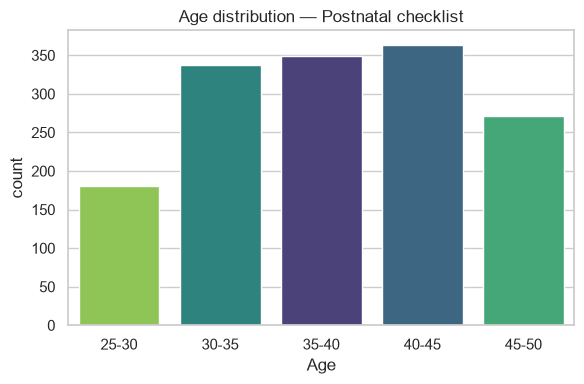

In [6]:
age_order = ["25-30", "30-35", "35-40", "40-45", "45-50"]
print(df["Age"].value_counts(dropna=False))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Age", order=age_order, hue="Age", palette="viridis", legend=False, ax=ax)
ax.set_title("Age distribution — Postnatal checklist")
plt.tight_layout()
save_fig(fig, "age_distribution.png", PROJECT_ROOT, dataset="postnatal")
plt.show()

In [7]:
symptom_cols = ["Feeling sad or Tearful", "Irritable towards baby & partner",
                "Trouble sleeping at night", "Problems concentrating or making decision",
                "Overeating or loss of appetite", "Feeling anxious", "Feeling of guilt",
                "Problems of bonding with baby", "Suicide attempt"]

for col in symptom_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- Feeling sad or Tearful ---
Feeling sad or Tearful
Yes          536
No           524
Sometimes    443
Name: count, dtype: int64

--- Irritable towards baby & partner ---
Irritable towards baby & partner
Yes          555
No           499
Sometimes    443
NaN            6
Name: count, dtype: int64

--- Trouble sleeping at night ---
Trouble sleeping at night
Two or more days a week    640
Yes                        445
No                         418
Name: count, dtype: int64

--- Problems concentrating or making decision ---
Problems concentrating or making decision
No       583
Often    473
Yes      435
NaN       12
Name: count, dtype: int64

--- Overeating or loss of appetite ---
Overeating or loss of appetite
No            841
Yes           343
Not at all    319
Name: count, dtype: int64

--- Feeling anxious ---
Feeling anxious
Yes    980
No     523
Name: count, dtype: int64

--- Feeling of guilt ---
Feeling of guilt
No       624
Maybe    528
Yes      342
NaN        9
Name: count, d

Saved figure: C:\maternal-mental-health-risk\reports\figures\postnatal\symptom_item_distributions.png


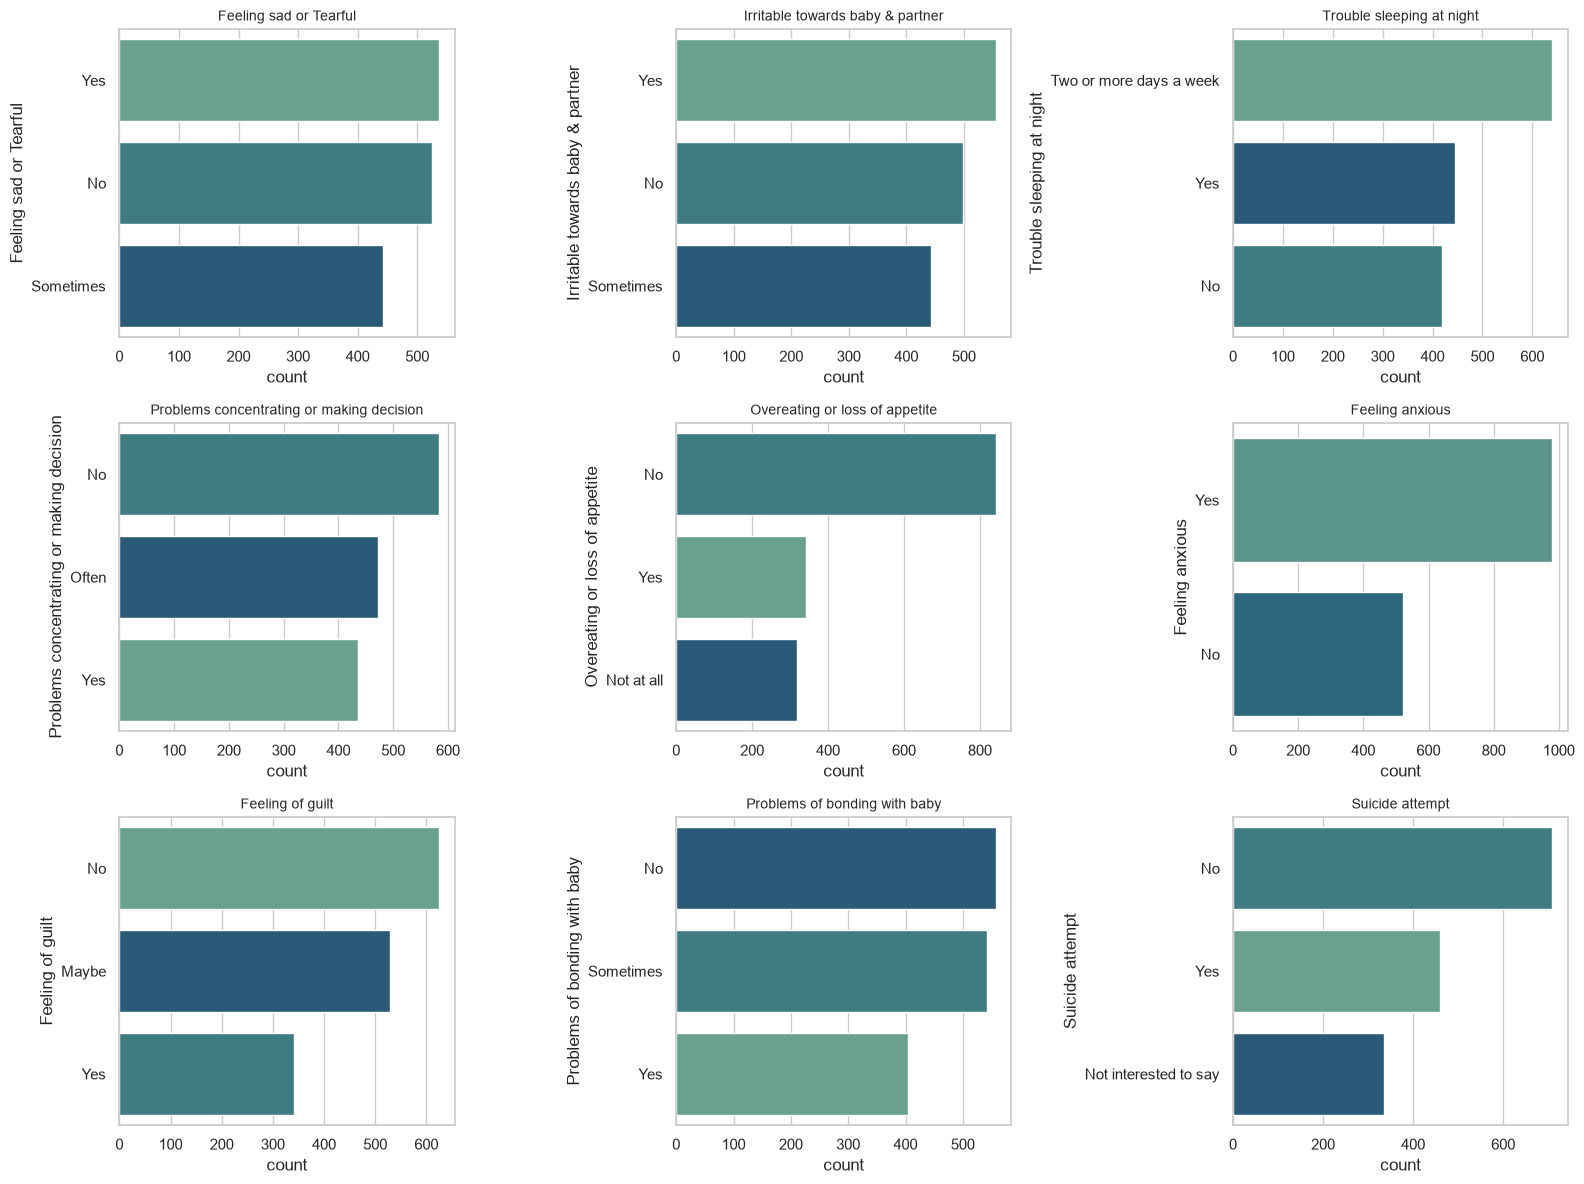

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, symptom_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, hue=col, palette="crest", legend=False, ax=ax)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
save_fig(fig, "symptom_item_distributions.png", PROJECT_ROOT, dataset="postnatal")
plt.show()

In [9]:
for col in symptom_cols:
    levels = df[col].dropna().unique().tolist()
    print(f"{col}: {levels}")

# Notice: some items are 2-level (Yes/No), others are 3-level with different wording
# each time ("Sometimes", "Often", "Not at all", "Maybe", "Not interested to say").
# There's also no outcome column in this file at all — a proxy label will need to be
# constructed from these items in 03_label_construction.ipynb, and documented as an
# investigator-defined limitation (this dataset has no gold-standard label).

Feeling sad or Tearful: ['Yes', 'No', 'Sometimes']
Irritable towards baby & partner: ['Yes', 'No', 'Sometimes']
Trouble sleeping at night: ['Two or more days a week', 'No', 'Yes']
Problems concentrating or making decision: ['Yes', 'No', 'Often']
Overeating or loss of appetite: ['Yes', 'No', 'Not at all']
Feeling anxious: ['Yes', 'No']
Feeling of guilt: ['No', 'Yes', 'Maybe']
Problems of bonding with baby: ['Yes', 'Sometimes', 'No']
Suicide attempt: ['Yes', 'No', 'Not interested to say']


Saved figure: C:\maternal-mental-health-risk\reports\figures\postnatal\symptoms_by_age.png


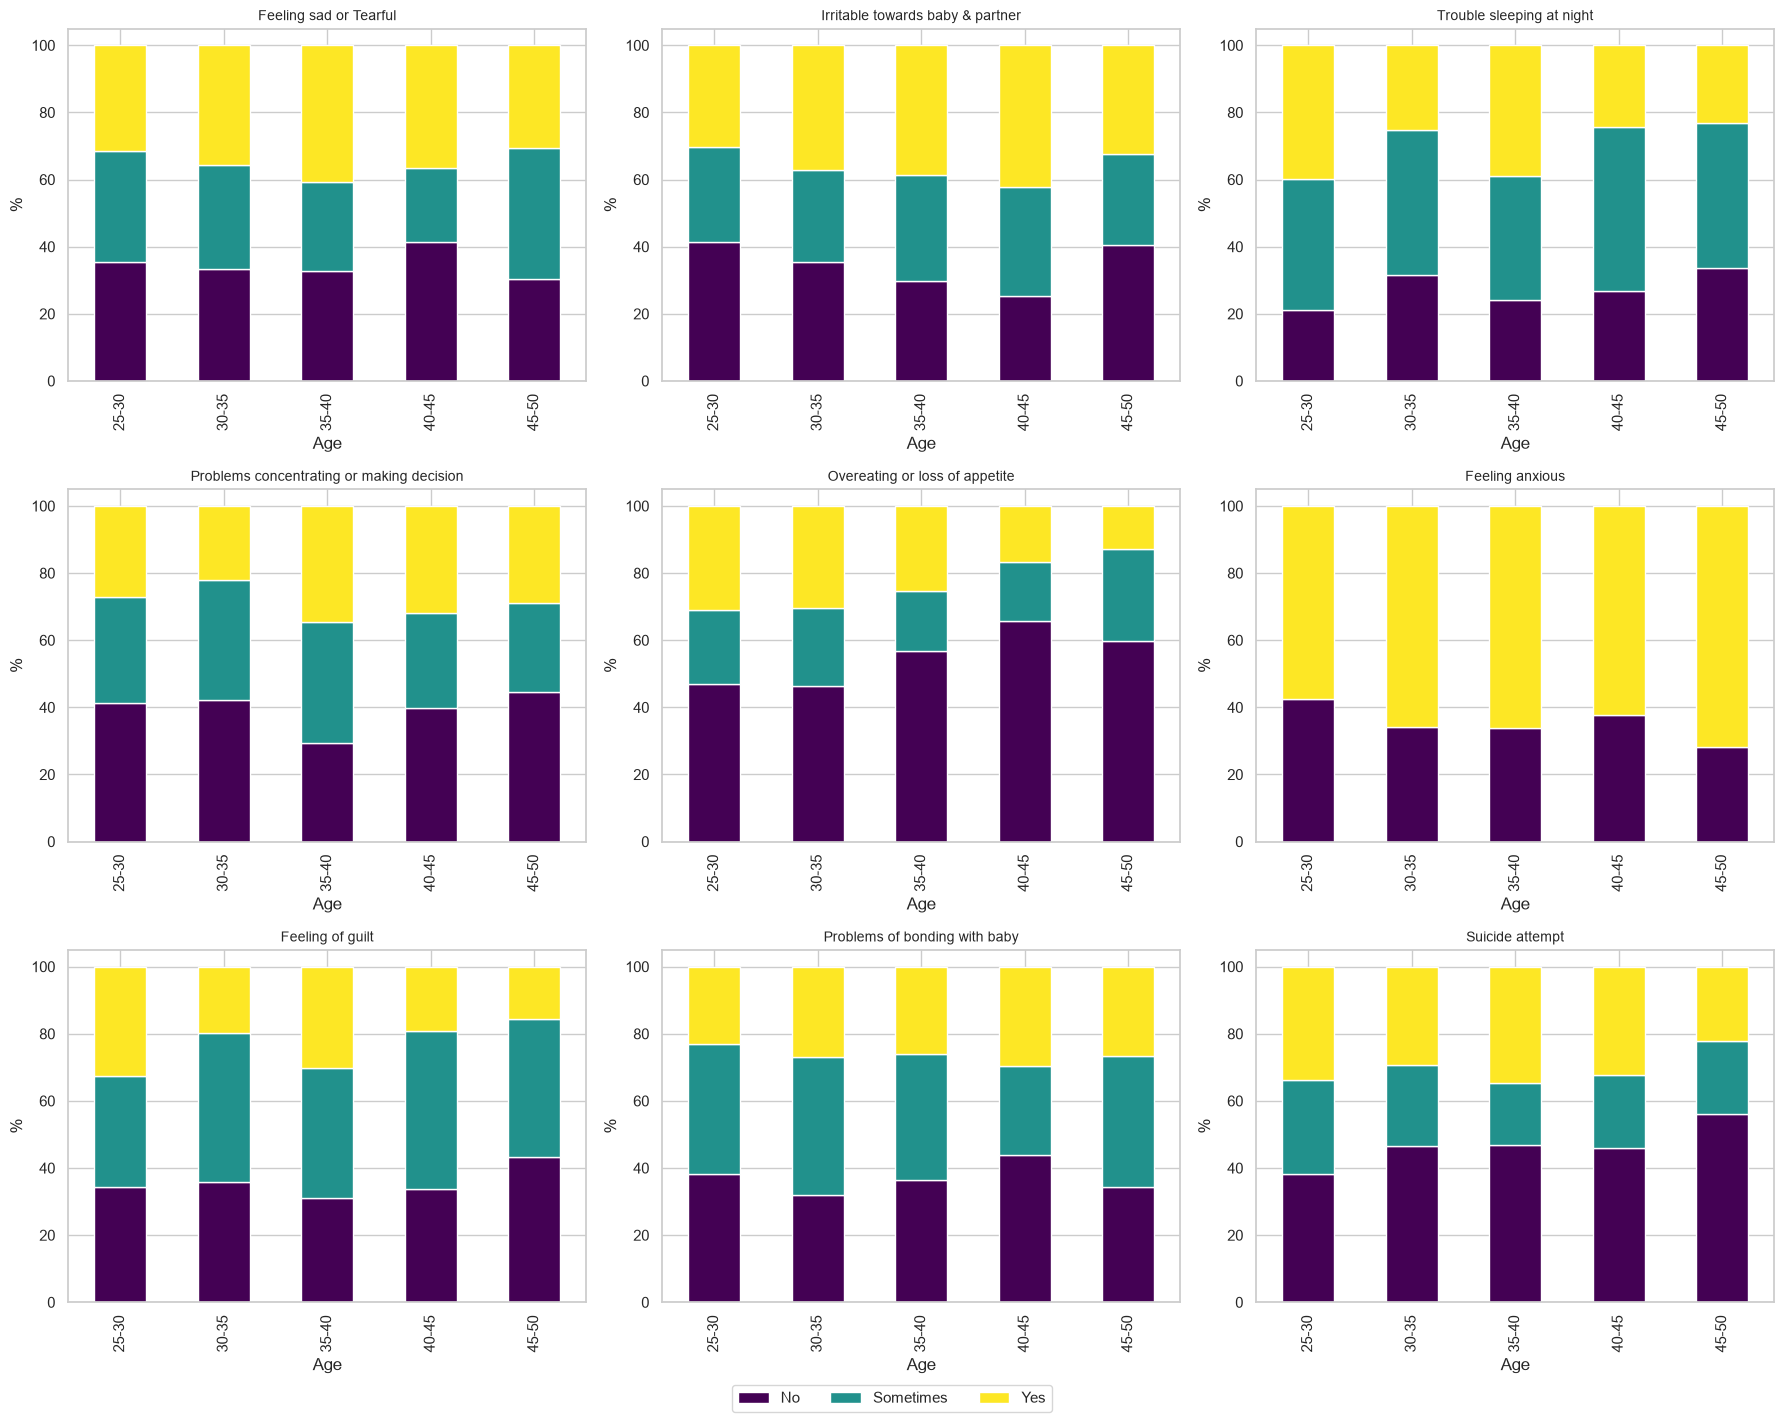

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.flat, symptom_cols):
    ct = pd.crosstab(df["Age"], df[col], normalize="index") * 100
    ct = ct.reindex(age_order)
    ct.plot(kind="bar", stacked=True, ax=ax, colormap="viridis", legend=False)
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("%")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout()
save_fig(fig, "symptoms_by_age.png", PROJECT_ROOT, dataset="postnatal")
plt.show()